In [ ]:
import pandas as pd

In [ ]:
df = pd.read_csv("bike-sharing-demand.csv")

In [ ]:
df.head(5) #checking first 5 lines of the file

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


# **Data Fields**
* **datetime** - hourly date + timestamp  
* **season** -  1 = spring, 2 = summer, 3 = fall, 4 = winter
* **holiday** - whether the day is considered a holiday
* **workingday** - whether the day is neither a weekend nor holiday
* **weather** -
** 1: Clear, Few clouds, Partly cloudy, Partly cloudy
** 2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist
** 3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds
** 4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog
**temp** - temperature in Celsius

*   **atemp** - "feels like" temperature in Celsius
*   **humidity** - relative humidity
*  **windspeed** - wind speed
* **casual** - number of non-registered user rentals initiated
* **registered** - number of registered user rentals initiated
* **count** - number of total rentals

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10886 entries, 0 to 10885
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10886 non-null  object 
 1   season      10886 non-null  int64  
 2   holiday     10886 non-null  int64  
 3   workingday  10886 non-null  int64  
 4   weather     10886 non-null  int64  
 5   temp        10886 non-null  float64
 6   atemp       10886 non-null  float64
 7   humidity    10886 non-null  int64  
 8   windspeed   10886 non-null  float64
 9   casual      10886 non-null  int64  
 10  registered  10886 non-null  int64  
 11  count       10886 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 1020.7+ KB


In [ ]:
# Let find the total bikes that got registred during 1 year
total_bike_count = df['count'].sum()
print(f'During 2011 : {total_bike_count} bike were registered')

During 2011 : 2085476 bike were registered


In [ ]:
total_casual_count = df['casual'].sum()
total_casual_count

392135

In [ ]:
total_registred_count = df['registered'].sum()
total_registred_count

1693341

In [ ]:
print(f'Percentage of Guest User Registrations {total_casual_count/total_bike_count *100} %')

Percentage of Guest User Registrations 18.8031413451893 %


In [ ]:
print(f'Percentage of Guest User Registrations {total_registred_count/total_bike_count *100} perct')

Percentage of Guest User Registrations 81.1968586548107 perct


## Effect of Season on Bike Registration
season - 1 = spring, 2 = summer, 3 = fall, 4 = winter

In [ ]:
#filtering the data in pandas
df[df['season']==1]['count'].sum() # returns all the rows where season column value is 1

312498

In [ ]:
df[df['season']==2]['count'].sum()

588282

In [ ]:
df[df['season']==3]['count'].sum()

640662

In [ ]:
df[df['season']==4]['count'].sum()

544034

## Group-by in pandas

<AxesSubplot: xlabel='season'>

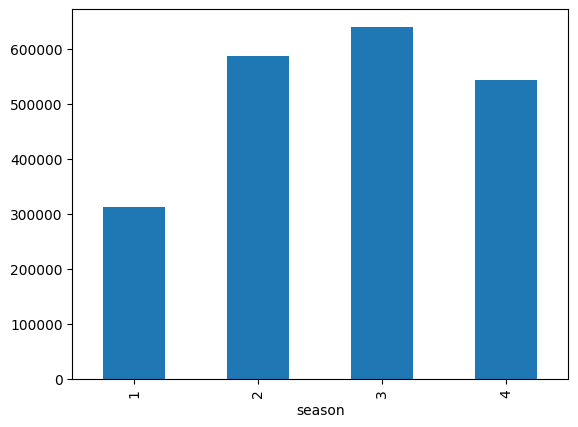

In [ ]:
df.groupby('season')['count'].sum().plot.bar()

In [ ]:
df.sample(5)

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
861,2011-02-19 08:00:00,1,0,0,1,15.58,19.695,17,39.0007,9,36,45
4200,2011-10-07 01:00:00,4,0,1,1,18.04,21.970,88,0.0000,3,25,28
251,2011-01-11 20:00:00,1,0,1,3,6.56,7.575,93,12.9980,0,32,32
2488,2011-06-11 14:00:00,2,0,0,1,33.62,38.635,49,7.0015,148,232,380
295,2011-01-13 18:00:00,1,0,1,1,8.20,9.090,40,22.0028,3,141,144


In [ ]:
def get_month(timestamp):
    month = int(timestamp[5:7])
    return month

In [ ]:
get_month("2011-06-11 14:00:00")

6

In [ ]:
df['month'] = df['datetime'].apply(get_month)

In [ ]:
df.head(5)

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,month
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,1
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,1
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,1
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,1


<AxesSubplot: xlabel='month'>

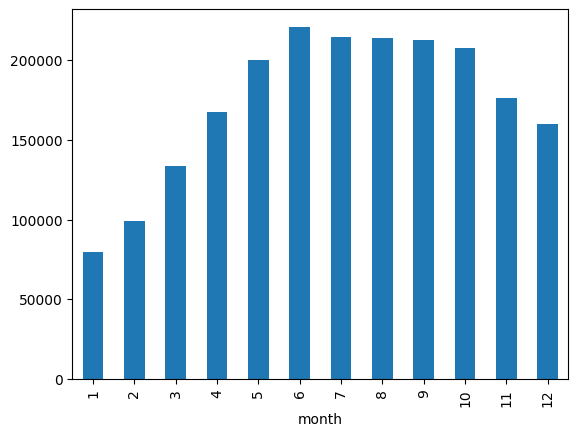

In [ ]:
df.groupby('month')['count'].sum().plot.bar()

In [ ]:
def get_hour(timestamp):
    hour = int(timestamp[11:13])
    return hour

In [ ]:
get_hour("2011-06-11 14:00:00")

14

In [ ]:
df['hour']=df['datetime'].apply(get_hour)

In [ ]:
df.head(5)

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,month,hour
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,1,0
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,1,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,1,2
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,1,3
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,1,4


<AxesSubplot: xlabel='hour'>

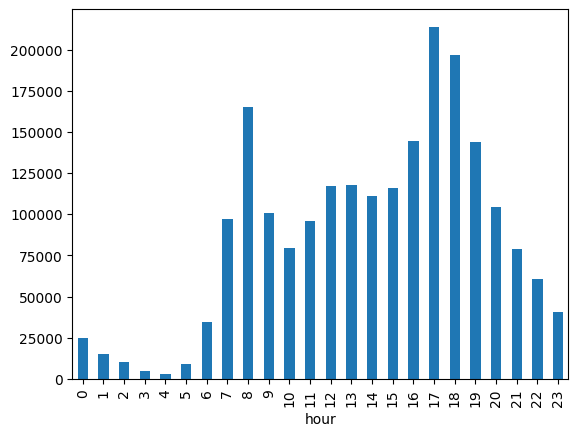

In [ ]:
df.groupby('hour')['count'].sum().plot.bar()

<AxesSubplot: xlabel='hour'>

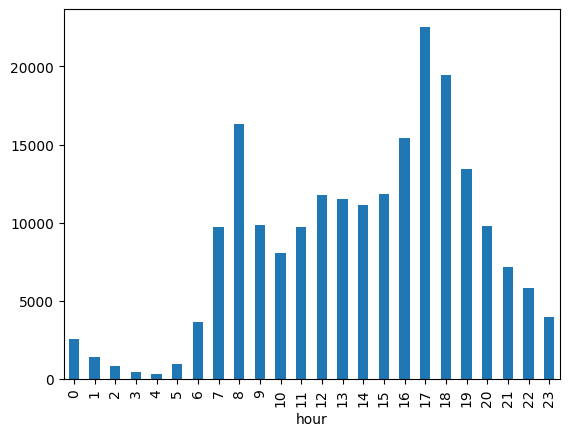

In [ ]:
df[df['month']==10].groupby('hour')['count'].sum().plot.bar()

## HomeWork : To analyse the weather and holiday trend in the data

In [ ]:
df1 = pd.DataFrame({"emp_id":[1,2,3,4],
                   "name":['li','max','nina','amit'],
                   "age":[39,40,32,41]})
df1 # HR -data

,emp_id,name,age
0,1,li,39
1,2,max,40
2,3,nina,32
3,4,amit,41


In [ ]:
df2 = pd.DataFrame({'emp_id':[1,2,3,4],
                   "salary":[200,310,400,280]})

In [ ]:
df2 # Account Department

,emp_id,salary
0,1,200
1,2,310
2,3,400
3,4,280


In [ ]:
# Join in Pandas

In [ ]:
df3 = pd.merge(df1,df2, on ="emp_id")

In [ ]:
df3[df3['age']>=40]['salary'].sum()

590